### EDA on Retail Sales
##### Objective: Perform a thorough Exploratory Data Analysis on a retail sales dataset to uncover patterns, customer behavior trends, and actionable business insights.

In [1]:
# Import pandas, matplotlib, & seaborn

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load E-commerce dataset

sales = pd.read_csv('ecommerce_sales_raw.csv')

In [3]:
sales.head(3)

,OrderID,OrderDate,CustomerName,Age,Gender,Region,Product,Category,Quantity,UnitPrice,Discount,ShippingCost,PaymentMethod,OrderStatus,GrossRevenue,NetRevenue
0,1017,1/14/2025,Aisha Sharma,28,Female,South,Running Shoes,Sports & Fitness,5,59.99,0.20,9.69,Credit Card,Delivered,299.95,239.9600
1,1164,3/26/2025,Emma Brown,30,Female,South,Wireless Mouse,Electronics,1,15.99,0.05,10.05,Credit Card,Delivered,15.99,15.1905
2,1016,5/27/2025,Grace Rodriguez,24,Female,North,Backpack,"Home, Office & Lifestyle",1,45.00,0.15,7.52,Credit Card,Delivered,45.00,38.2500


In [4]:
# Check the size of the dataset 
sales.shape

(320, 16)

In [5]:
# Columns data types
sales.dtypes

OrderID            int64
OrderDate         object
CustomerName      object
Age                int64
Gender            object
Region            object
Product           object
Category          object
Quantity           int64
UnitPrice        float64
Discount         float64
ShippingCost     float64
PaymentMethod     object
OrderStatus       object
GrossRevenue     float64
NetRevenue       float64
dtype: object

In [6]:
# Check for null values
sales.isnull().sum()

OrderID          0
OrderDate        0
CustomerName     0
Age              0
Gender           0
Region           0
Product          0
Category         0
Quantity         0
UnitPrice        0
Discount         0
ShippingCost     0
PaymentMethod    0
OrderStatus      0
GrossRevenue     0
NetRevenue       0
dtype: int64

In [7]:
# Descriptive Stats of all columns
sales.describe()

,OrderID,Age,Quantity,UnitPrice,Discount,ShippingCost,GrossRevenue,NetRevenue
count,320.000000,320.000000,320.000000,320.000000,320.000000,320.000000,320.000000,320.000000
mean,1160.500000,47.678125,2.362500,22.466062,0.078438,7.593719,53.554625,49.250037
std,92.520268,17.047035,1.343684,16.513913,0.076997,2.413858,55.210878,50.820865
min,1001.000000,18.000000,1.000000,6.500000,0.000000,3.510000,6.500000,5.200000
25%,1080.750000,34.000000,1.000000,9.990000,0.000000,5.597500,18.750000,16.956000
50%,1160.500000,47.000000,2.000000,15.990000,0.050000,7.405000,34.500000,31.980000
75%,1240.250000,63.250000,3.000000,34.500000,0.150000,9.690000,63.960000,59.990000
max,1320.000000,75.000000,5.000000,59.990000,0.200000,11.980000,299.950000,299.950000


In [8]:
# Convert OrderDate to the right data type
sales['OrderDate'] = pd.to_datetime(sales['OrderDate'])

sales['OrderDate'].dtype

dtype('<M8[ns]')

In [9]:
# Extract month and quarter from OrderDate
sales['MonthName'] = sales['OrderDate'].dt.month_name()
sales['MonthNumber'] = sales['OrderDate'].dt.month
sales['Quarter'] = "Q" + sales['OrderDate'].dt.quarter.astype(str)

In [10]:
sales.head(3)

,OrderID,OrderDate,CustomerName,Age,Gender,Region,Product,Category,Quantity,UnitPrice,Discount,ShippingCost,PaymentMethod,OrderStatus,GrossRevenue,NetRevenue,MonthName,MonthNumber,Quarter
0,1017,2025-01-14,Aisha Sharma,28,Female,South,Running Shoes,Sports & Fitness,5,59.99,0.20,9.69,Credit Card,Delivered,299.95,239.9600,January,1,Q1
1,1164,2025-03-26,Emma Brown,30,Female,South,Wireless Mouse,Electronics,1,15.99,0.05,10.05,Credit Card,Delivered,15.99,15.1905,March,3,Q1
2,1016,2025-05-27,Grace Rodriguez,24,Female,North,Backpack,"Home, Office & Lifestyle",1,45.00,0.15,7.52,Credit Card,Delivered,45.00,38.2500,May,5,Q2


In [11]:
# Colors
PRIMARY = '#2C3E90'
ACCENT = '#E8A33D'

In [12]:
# Category colors
CATEGORY_COLORS = {
    'Electronics': '#2C3E90',
    'Home, Office & Lifestyle': '#E8A33D',
    'Sports & Fitness': '#4C956C'
}

In [13]:
# Monthly sales analysis
Monthly_Sales = sales.groupby('MonthName')['NetRevenue'].sum()
Monthly_Sales

MonthName
April       1962.1770
February    1932.9360
January     3187.9455
June        2540.1715
March       3521.5185
May         2615.2635
Name: NetRevenue, dtype: float64

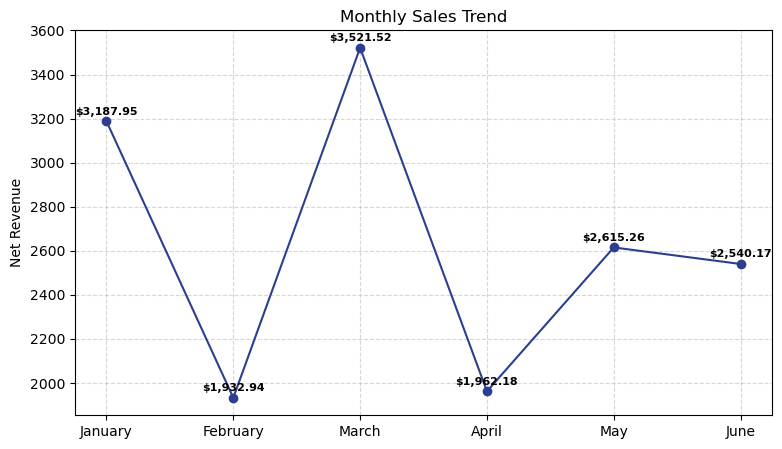

In [14]:
# Monthly sales trend
## Sort 
Month_Order = ['January', 'February', 'March',
               'April', 'May', 'June']
Monthly_Sales = Monthly_Sales.reindex(Month_Order)

# Plot 
plt.figure(figsize=(9,5))
plt.plot(Monthly_Sales.index, Monthly_Sales.values, marker='o', linestyle='-', color=PRIMARY)
plt.ylabel('Net Revenue')
plt.title('Monthly Sales Trend')

# Add value labels 
for x, y in zip(Monthly_Sales.index, Monthly_Sales.values):
    plt.text(x, y + 30, f'${y:,.2f}', ha='center', fontsize=8, fontweight='semibold')

plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Net revenue swings sharply from month to month across the six-month period, with no steady upward or downward trend. March is the clear peak(USD 3,521.52), nearly double the two lowest points, February and April, which sit at almost identical threshold. After the April low, revenue recovers over May (USD 2,615.26) and June (USD 2,540.17), but plateaus rather than continuing to climb. June is essentially flat compared to May, and the January or March highs. 

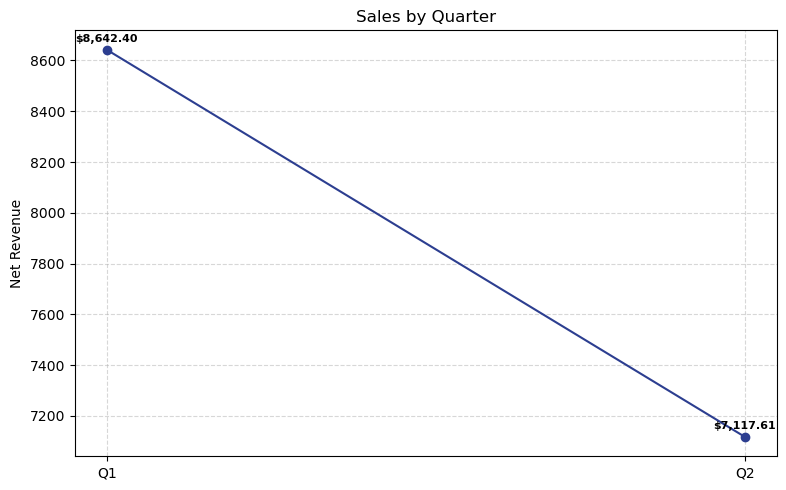

In [15]:
# Quarterly sales analysis
Quarterly_Sales = sales.groupby('Quarter')['NetRevenue'].sum()

# Plot 
plt.figure(figsize=(8,5))
plt.plot(Quarterly_Sales.index, Quarterly_Sales.values, marker='o', linestyle='-', color=PRIMARY)
plt.ylabel('Net Revenue')
plt.title('Sales by Quarter')

# Add value labels 
for x, y in zip(Quarterly_Sales.index, Quarterly_Sales.values):
    plt.text(x, y + 30, f'${y:,.2f}', ha='center', fontsize=8, fontweight='semibold')
    
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Net revenue declined from USD 8,642.40 in Q1 to USD 7,117.61 in Q2, a drop of USD 1,524.79, or about 17.6%. This confirms a genuine quarter-over-quarter slowdown. Looking at the monthly breakdown, the decline appears driven mainly by the loss of Q1's standout month - March (USD 3,521.52) which pulled the Q1 average up; Q2's three months are more consistent with each other (USD 1,962 - USD 2,540.17) but collectively fall short of replicating a peak month like March. This suggest the Q1-to-Q2 dip may reflect the absence of a high-performing month in Q2 rather than a broad decline across all months.

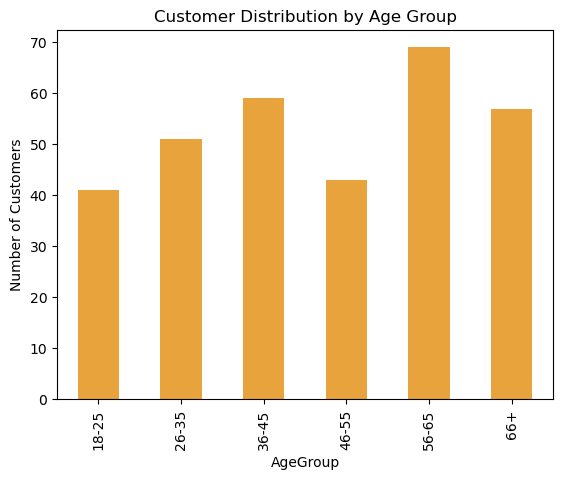

In [16]:
# Age group distribution
bins = [18, 25, 35, 45, 55, 65, 75]
labels = ['18-25', '26-35', '36-45', '46-55', '56-65', '66+']
sales['AgeGroup'] = pd.cut(sales['Age'], bins=bins, labels=labels, include_lowest=True)

Age_Dist = sales['AgeGroup'].value_counts().sort_index()
Age_Dist.plot(kind='bar', color=ACCENT)
plt.title('Customer Distribution by Age Group')
plt.ylabel('Number of Customers')
plt.show()

Customer distribution across age groups is fairly broad, with no single group dominating. The 56-65 age group has the highest customer count (about 70 counts), follow by 36-45 (about 59 counts) and 66+ (about 57 counts), while 18-25 has the fewest customers (about 41 counts). This suggests the customer base skews toward middle-aged and older adults rather than younger shoppers, which could inform targeted marketing.

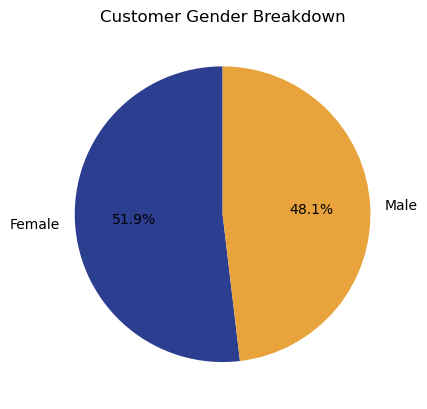

In [17]:
# Gender breakdown
Gender_Dist = sales['Gender'].value_counts()
Gender_Dist.plot(kind='pie', autopct='%1.1f%%', colors=[PRIMARY, ACCENT], startangle=90)
plt.title('Customer Gender Breakdown')
plt.ylabel('')
plt.show()

The customer base is nearly evenly by split by gender, with females making up 51.9% and males 48.1% which is a difference of less than 4 percentage points. This near-balanced split suggests the business doesn't have a strongly gender-skewed customer base, meaning marketing and product strategies likely doesn't need heavy gender-specific targeting, and campaigns can reasonably appeal to both segments without excluding either.

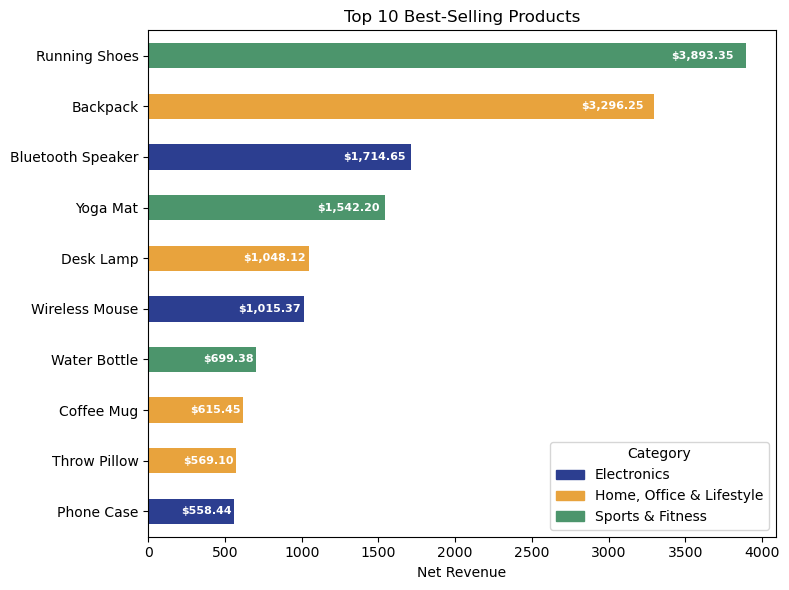

In [18]:
# Product analysis
## Top 10 best-selling products
Product_Sales = sales.groupby('Product')['NetRevenue'].sum()
# Sort in descending order and take the top 10
Top_10_Products = Product_Sales.sort_values(ascending=False).head(10)

## Get each top-10 product's category
product_category_map = sales.groupby('Product')['Category'].first()

# Reorder to match Top_10_Products index, then map colors
top_10_colors = [CATEGORY_COLORS[product_category_map[p]] for p in Top_10_Products.sort_values().index]

# Plot
plt.figure(figsize=(8, 6))
Top_10_Products.sort_values().plot(kind='barh', color=top_10_colors)
plt.xlabel('Net Revenue')
plt.ylabel('')
plt.title('Top 10 Best-Selling Products')

# Add value labels inside each bar
for i, v in enumerate(Top_10_Products.sort_values()):
    plt.text(v - (v * 0.02), i, f'${v:,.2f}', va='center', ha='right', 
                    fontsize=8, color='white', fontweight='bold')

# Add legend
from matplotlib.patches import Patch

legend_handles = [Patch(color=color, label=cat) for cat, color in CATEGORY_COLORS.items()]
plt.legend(handles=legend_handles, title='Category', loc='lower right')

plt.tight_layout()
plt.show()

Running Shoes (USD 3,893.35) and Backpack (USD 3,296.25) are by far the top revenue-generating products, together are nearly as much as the remaining eight products. There's a sharp drop-off after these two top products, Bluetooth Speaker (USD 1,714.65) is the third-highest but sits at less than half of Running Shoe's revenue. The bottom of the list (Throw Pillow at USD 569.10 and Phone Case, roughly USD 558) contributes comparatively little, suggesting the business's revenue is concentrated in a small number of high-performing products. This concentration is worth flagging: prioritizing inventory, marketing, and promotions around Running Shoes and Backpacks could yield outsized returns, while the lower-performing items may need bundling, discounting, or a review of whether they're worth continued stocking.

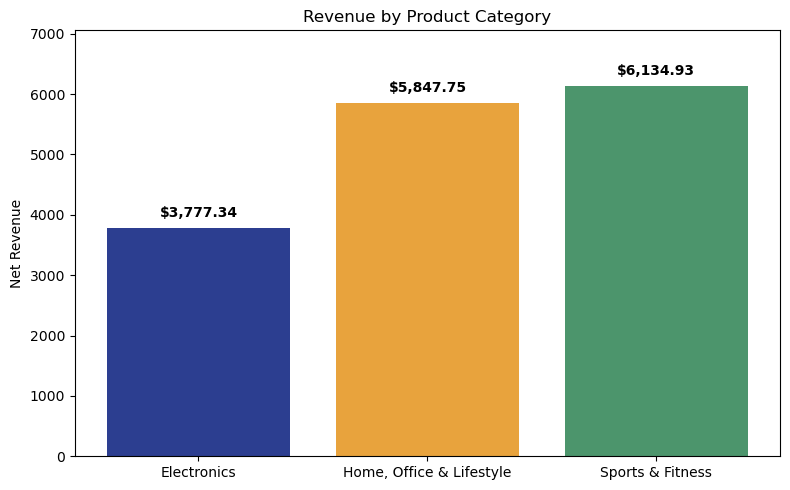

In [19]:
# Revenue by product category
Product_Category = sales.groupby('Category')['NetRevenue'].sum()

# Plot
plt.figure(figsize=(8, 5))
colors = [CATEGORY_COLORS[cat] for cat in Product_Category.index]
plt.bar(Product_Category.index, Product_Category.values, color=colors)
plt.title('Revenue by Product Category')
plt.xlabel('')
plt.ylabel('Net Revenue')

# Add value labels above each bar
offset = Product_Category.max() * 0.03 # 3% of the tallest bar's height
for i, v in enumerate(Product_Category.values):
    plt.text(i, v + offset, f'${v:,.2f}', ha='center', fontweight='bold')

# Give the chart some headroom so labels aren't cut off at the top
plt.ylim(0, Product_Category.max() * 1.15)

plt.tight_layout()
plt.show()

Sport & fitness leads in revenue (USD 6,134.93), closely followed by Home, Office & Lifestyle (USD 5,847.75), while Electronics trails noticeably behind at USD 3,777.34 which is roughly 38% lower than the top category. This aligns with the earlier product-level finding that Running Shoes and Backpacks (both part of Sport & fitness / Lifestyle categories) are the standout best-sellers, reinforcing that lifestyle and fitness-related products are the primary revenue drivers. Electronics, despite typically being a high-ticket category, underperforms here, suggesting either fewer electronics products in the catalog, lower demand, or an opportunity to expand marketing/inventory in that category to close the gap.

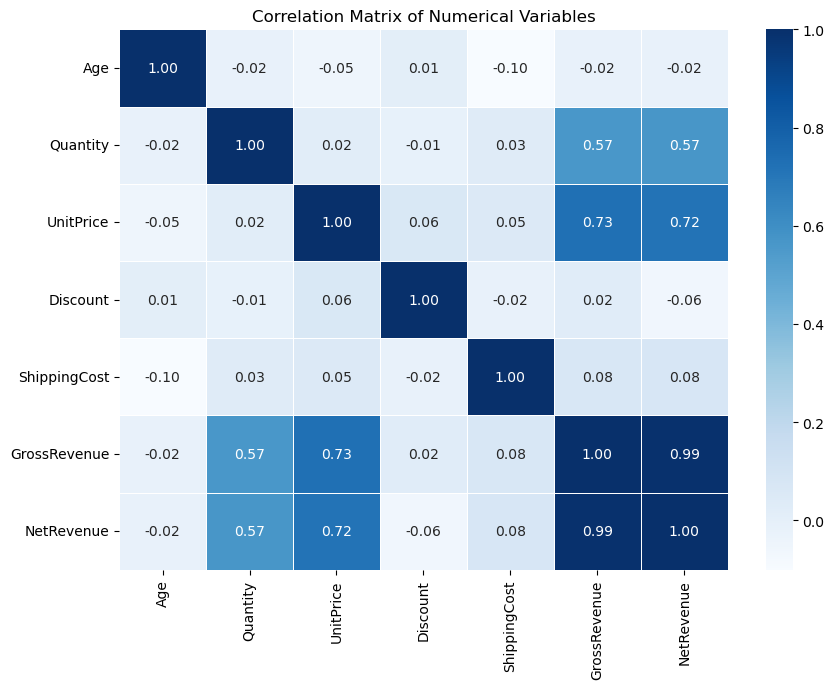

In [20]:
# Correlation heatmap
exclude_cols = ['OrderID', 'MonthNumber']
numeric_cols = sales.select_dtypes(include='number').drop(columns=exclude_cols)

## Compute correlation matrix
corr_matrix = numeric_cols.corr()

# Plot
plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, cmap='Blues', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Numerical Variables')
plt.tight_layout()
plt.show()

After removing non-quantitative identifiers (OrderID, MonthNumber), the correlation matrix reveals a few meaningful relationships. GrossRevenue and NetRevenue are almost perfectly correlated (0.99), which make sense since NetRevenue is derived from GrossRevenue. Both revenue measures show a moderately strong positive correlation with UnitPrice (0.73 and 0.72) and Quantity (0.57 each), confirming that revenue is driven by a combination of how many units are sold and how much each unit costs, with price having a slightly stronger influence than quantity. Age, Discount, and ShippingCost show negligible correlation (all near 0) with revenue or with each other, suggesting these variables don't meaningfully drive sales outcomes in this dataset. This indicates that pricing strategy and sales volume are the key levers for revenue growth, while discounting and shipping costs appear to have little measurable impact.

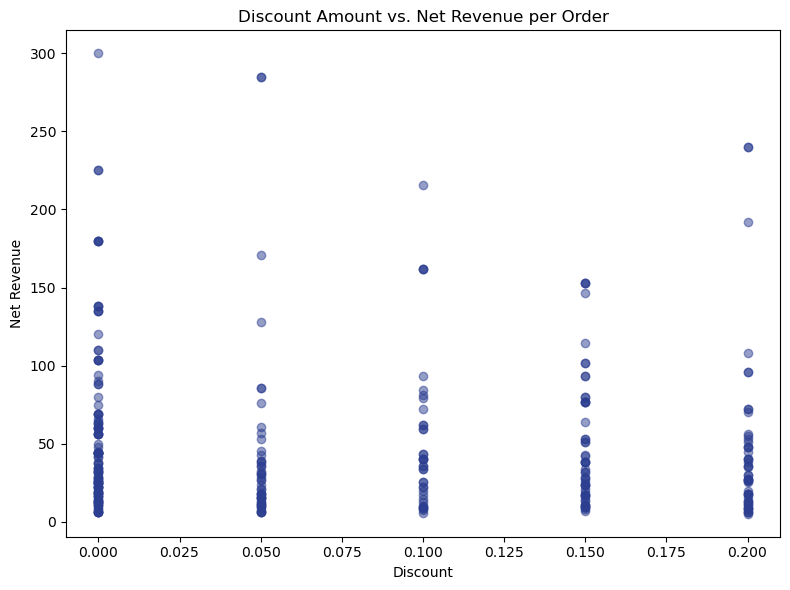

In [21]:
# Additional visualization
## Discount vs Net Revenue
plt.figure(figsize=(8, 6))
plt.scatter(sales['Discount'], sales['NetRevenue'], alpha=0.5, color=PRIMARY)
plt.title('Discount Amount vs. Net Revenue per Order')
plt.xlabel('Discount')
plt.ylabel('Net Revenue')
plt.tight_layout()
plt.show()

This scatter plot reveals a non-obvious insight: discount level shows no meaningful relationship with order value. Revenue is widely scattered (ranging from near USD 0 to over USD 300) at every discount tier, including 0% discount, which is where the single highest-revenue order (around USD 300) occurs. If discounts were effectively driving larger purchases, we'd expect revenue to trend upward as discount percentage increases; instead, the spread of revenue looks nearly identical across all discount levels (0%, 5%, 10%, 15%, 20%). This confirms what the earlier correlation heatmap suggested (Discount ≈ 0 correlation with revenue): discounts in this dataset are not incentivizing bigger orders. This is a valuable, non-obvious finding, it suggests the business may be giving away margin through discounts without a corresponding lift in order value, and could benefit from testing whether removing or restructuring discounts changes customer behavior

####  Conclusion & Business Recommendations
##### 1. Reassess the discount strategy.
Discount amount shows virtually no correlation with net revenue (≈0), and the single highest-revenue order occurred at 0% discount. This suggests discounts aren't driving larger purchases. Recommendation: Test reducing or removing discounts on select products to see if revenue holds, if so, the business can recover margin currently lost with a sales benefit.
##### 2. Double down on top-performing products and categories.
Running Shoes and Backpacks generates nearly as much revenue as the bottom eight products, and Sports & Fitness / Home, Office & Lifestyle categories significantly outperform Electronics. Recommendation: Prioritize marketing spend and inventory for top performers, and consider bundling or discounting consistently low-performing items like Phone Case and Throw Pillow.
##### 3. Investigate what drove the March revenue spike  and replicate it.
Q1-to-Q2 revenue dropped 17.6%, largerly because Q2 lacked a standout month comparable to March, which nearly doubled other month's revenue. Recommendation: Identify the cause of March's spike (promotion, seasonal demand, bulk order, etc.) and test replicating that driver in future months to reduce revenue volatility.